# 02 — Exploratory Data Analysis

Before any modeling: which column is actually the right thing to predict? `Annual_yield` looks
like the obvious modeling target by name, but this notebook shows why it's the wrong one.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/cleaned_farm_data.csv")
print(df.shape)
df.head(3)


(5654, 18)


## Is `Annual_yield` actually a yield, or just total output?

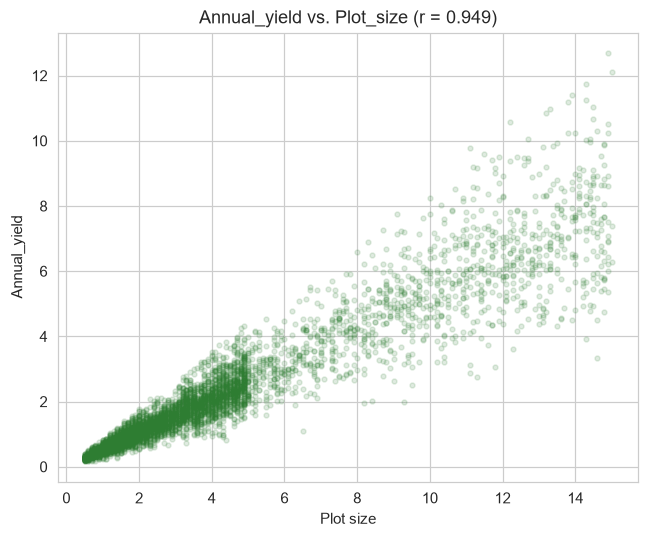

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df["Plot_size"], df["Annual_yield"], alpha=0.15, s=10, color="#2E7D32")
ax.set_xlabel("Plot size")
ax.set_ylabel("Annual_yield")
ax.set_title(f"Annual_yield vs. Plot_size (r = {df['Plot_size'].corr(df['Annual_yield']):.3f})")
plt.tight_layout()
plt.savefig("../images/yield_vs_plotsize.png", dpi=130, bbox_inches="tight")
plt.show()


**r = 0.95.** `Annual_yield` is almost entirely explained by farm size alone — it's total
harvest volume, not a per-area yield rate. A bigger farm produces more total output almost by
definition; that's not an interesting agronomic signal to model.

In [3]:
df["yield_per_ha"] = df["Annual_yield"] / df["Plot_size"]
print("Correlation: computed yield_per_ha vs. the existing 'Standard_yield' column:",
      round(df["yield_per_ha"].corr(df["Standard_yield"]), 6))
print("Correlation: Standard_yield vs. Plot_size:", round(df["Standard_yield"].corr(df["Plot_size"]), 4))


Correlation: computed yield_per_ha vs. the existing 'Standard_yield' column: 1.0
Correlation: Standard_yield vs. Plot_size: -0.017


**`Standard_yield` is, to six decimal places, exactly `Annual_yield / Plot_size`** (r = 1.0),
and — unlike `Annual_yield` — it's essentially uncorrelated with farm size (r = -0.02). Despite
its name suggesting a fixed per-crop benchmark, `Standard_yield` is actually the real per-hectare
yield rate for each field. **This, not `Annual_yield`, is the correct target for yield
prediction** — it's the column that actually varies with soil, weather, and farming conditions
rather than just farm size.

## Yield by crop type

            mean    std  count
Crop_type                     
tea        0.645  0.136    913
rice       0.587  0.074    265
potato     0.582  0.052    823
maize      0.531  0.078    399
wheat      0.516  0.089   1342
cassava    0.478  0.078    672
coffee     0.463  0.101    607
banana     0.462  0.080    633


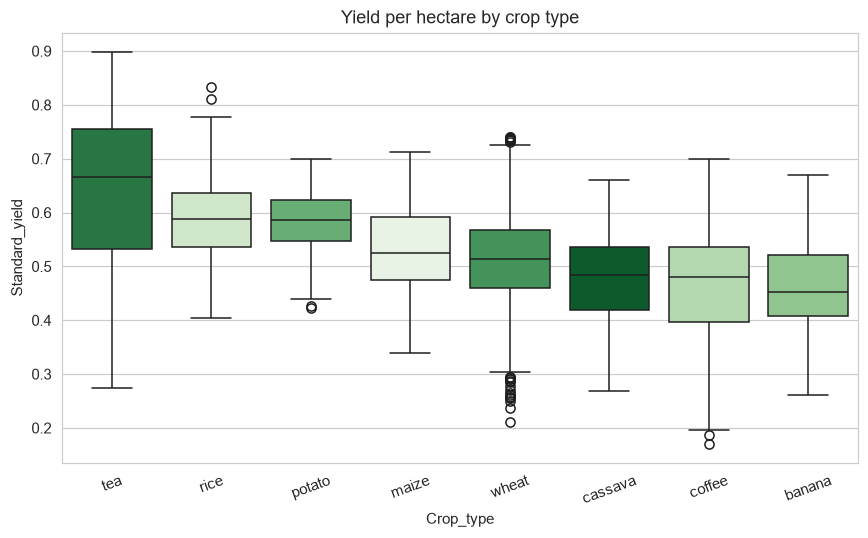

In [4]:
crop_yield = df.groupby("Crop_type")["Standard_yield"].agg(["mean", "std", "count"]).sort_values("mean", ascending=False)
print(crop_yield.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Crop_type", y="Standard_yield", ax=ax,
            order=crop_yield.index, palette="Greens_r", hue="Crop_type", legend=False)
ax.set_title("Yield per hectare by crop type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../images/yield_by_crop.png", dpi=130, bbox_inches="tight")
plt.show()


## Yield by province

Location
Rural_Sokoto      0.588
Rural_Kilimani    0.532
Rural_Akatsi      0.523
Rural_Amanzi      0.518
Rural_Hawassa     0.516
Name: Standard_yield, dtype: float64


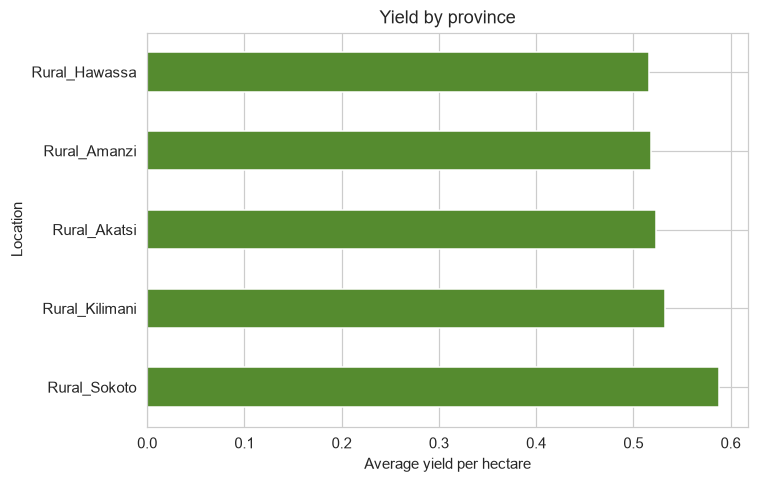

In [5]:
province_yield = df.groupby("Location")["Standard_yield"].mean().sort_values(ascending=False)
print(province_yield.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
province_yield.plot.barh(ax=ax, color="#558B2F")
ax.set_xlabel("Average yield per hectare")
ax.set_title("Yield by province")
plt.tight_layout()
plt.savefig("../images/yield_by_province.png", dpi=130, bbox_inches="tight")
plt.show()


## What correlates with yield?

Pollution_level   -0.285761
pH                -0.196613
Ave_temps          0.006786
Rainfall           0.039217
Slope              0.056991
Soil_fertility     0.070205
Elevation          0.102952
Name: Standard_yield, dtype: float64


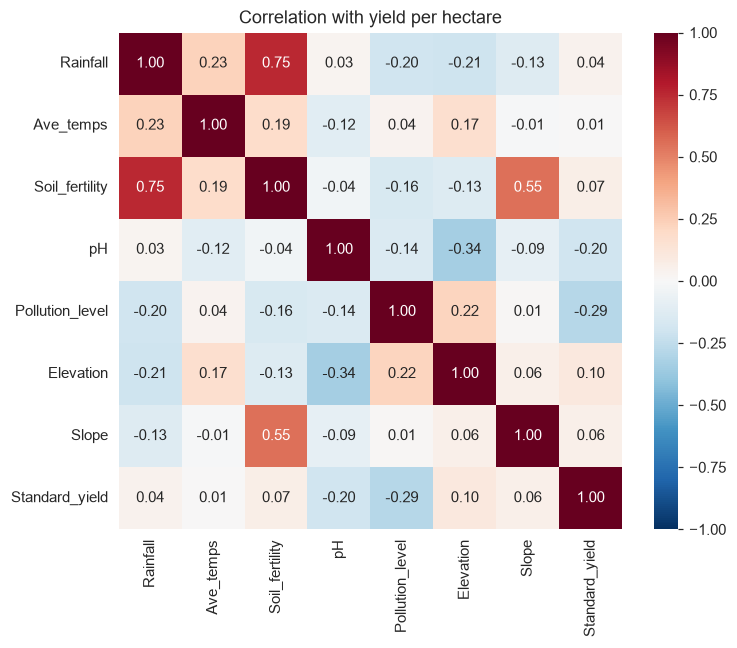

In [6]:
env_cols = ["Rainfall", "Ave_temps", "Soil_fertility", "pH", "Pollution_level", "Elevation", "Slope"]
corr = df[env_cols + ["Standard_yield"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, vmin=-1, vmax=1)
ax.set_title("Correlation with yield per hectare")
plt.tight_layout()
plt.savefig("../images/yield_correlation_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()

print(corr["Standard_yield"].drop("Standard_yield").sort_values())


**Pollution level has the strongest relationship with yield (r = -0.29)** — more polluted
soil, lower yield, which is agronomically sensible. pH is next (r = -0.20). Rainfall and
temperature show almost no linear relationship with yield in this dataset, which is a genuine,
slightly counter-intuitive finding worth carrying into the modeling notebook rather than assuming
weather must dominate.

## Soil type and yield

Soil_type
Volcanic    0.597
Loamy       0.580
Sandy       0.505
Rocky       0.498
Silt        0.493
Peaty       0.448
Name: Standard_yield, dtype: float64


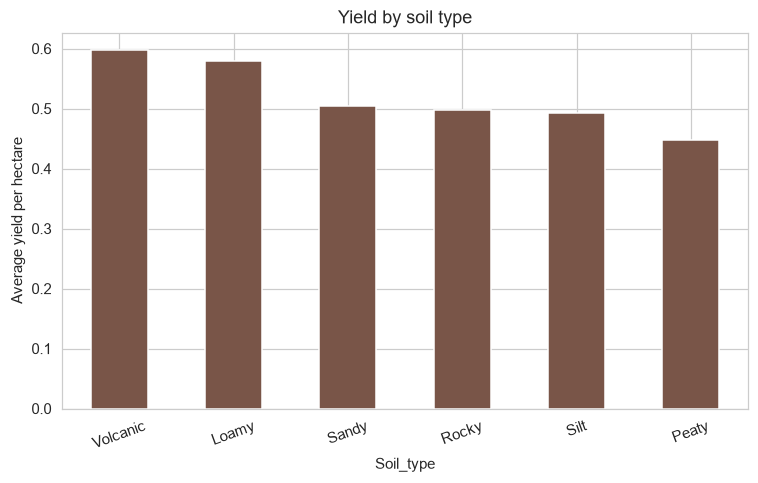

In [7]:
soil_yield = df.groupby("Soil_type")["Standard_yield"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
soil_yield.plot.bar(ax=ax, color="#795548")
ax.set_ylabel("Average yield per hectare")
ax.set_title("Yield by soil type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../images/yield_by_soil.png", dpi=130, bbox_inches="tight")
plt.show()
print(soil_yield.round(3))


## EDA takeaways carried into the ML notebook

1. `Annual_yield` is not a usable modeling target — it's ~farm size (r=0.95 with Plot_size).
   `Standard_yield` (= Annual_yield / Plot_size, discovered here) is the real per-hectare yield
   and is what gets modeled next.
2. Tea and rice have the highest average yield per hectare; cassava the lowest.
3. Pollution level and pH are the strongest (negative) environmental correlates of yield;
   rainfall and temperature show almost no linear relationship.
4. Sokoto has the highest average yield per hectare despite being the worst-served province for
   water access in the companion water-access-analytics project — these are two different
   Maji Ndogo datasets and no link between them is claimed here.
